# Determine hexagons

This notebook will be for the purposes of determining which hexagons I want to use when printing the LEJOG hexagons.

The spawn hexagon will be located in Cornwall, and subsequent hexagons will be appended from there to fill the mainland UK.

In [1]:
# standard imports
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.mplot3d import Axes3D

mpl.rc('image', cmap='terrain')

import topohex as tph

#import loadData as LD
#import CoordinateTransform as CT
#import Hexagon as Hexagon
#import HexGrid as HexGrid

## Loading in topographical data

The topographical data is stored in the files `./data/srtm/srtm_##_##.asc` with the relevant projection data being in the equivalent `.prj` file. For this project, we have:

| 35_01 | 36_01 | --    |
|-------|-------|-------|
| **35_02** | **36_02** | **37_02** |

*NOTE*: `37_01` is missing, which would otherwise include mostly empty ocean. For the sake of generating a rectangular array of data, thiss will be filled with `sea_value` data. 

In [2]:
%%time
sea_value = -200

n_rows, n_cols = 6000,6000 # default hard coded values obtained from .asc files

relative_path = ['.', 'data', 'srtm']
load_dir = os.path.join(*relative_path)
# values returned from tph.loadData.load_asc_format are the data, and the metadata for the grid

def load_asc(names):
    loaded_data = {}
    for name in names:
        fname = f'srtm_{name}.asc'
        try:
            D, m = tph.load.load_asc_format(load_dir, fname, seaVal=sea_value)
        except Exception as err: # assume exceptions arise from non-existant files, replace with sea val grid
            print(f'{name} => {err}')
            D = np.full( (n_rows, n_cols), sea_value )
        loaded_data[name] = D
    
    return loaded_data

names = (
    '35_01', '35_02',
    '36_01', '36_02',
    '37_01', '37_02',
)

loaded_data = load_asc(names)

for n, v in loaded_data.items():
    print(f'{n:>10} | {v.shape} | {np.min(v)} | {np.max(v)}')

37_01 => [Errno 2] No such file or directory: './data/srtm/srtm_37_01.asc'
     35_01 | (6000, 6000) | -200.0 | 1335.0
     35_02 | (6000, 6000) | -200.0 | 1018.0
     36_01 | (6000, 6000) | -200.0 | 1309.0
     36_02 | (6000, 6000) | -200.0 | 1058.0
     37_01 | (6000, 6000) | -200 | -200
     37_02 | (6000, 6000) | -200.0 | 446.0
CPU times: user 30.6 s, sys: 602 ms, total: 31.2 s
Wall time: 31.5 s


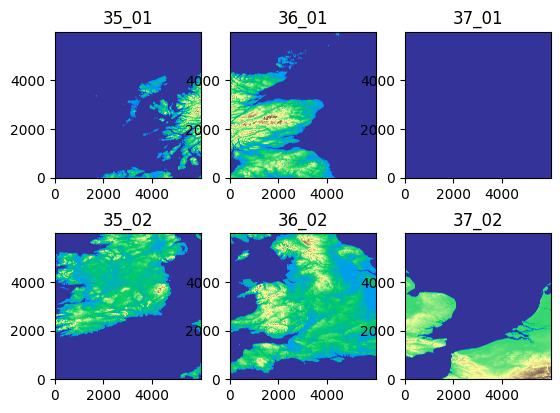

<Figure size 640x480 with 0 Axes>

In [3]:
fig, axs = plt.subplots(2,3)

row_names = (
    ('35_01', '36_01', '37_01'),
    ('35_02', '36_02', '37_02')
)

for r_axs, r_names in zip(axs, row_names):
    for ax, name in zip(r_axs, r_names):
        if name is None:
            continue
        ax.imshow(loaded_data[name], aspect='equal', origin='lower')
        ax.set_title(name)

plt.show()
plt.clf()

## Masking data

I don't want to include France or Ireland (nothing personal) so its time to wipe them off the map...

This will be done by simple indexing into the array and setting values to the `sea_value` value.

### Ireland

Ireland is present in `35_01` and `35_02`.

#### `35_01`
In this one, it appears fairly simple to remove, simply masking $x \in [0,500]$ and $y \in [0,4840]$

#### `35_02`
In this one, its a little more complicated because of Wales (damnit Wales.) In the end though, it can still be done with a single rectanglular selection

We can easily remove the rectangle $x \in [0,5480]$ and $y \in [1700, 6000]$

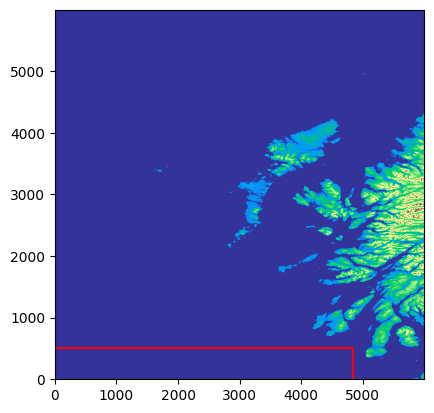

CPU times: user 859 ms, sys: 7.07 ms, total: 866 ms
Wall time: 865 ms


<Figure size 640x480 with 0 Axes>

In [42]:
%%time
# lets start with Ireland...
new_35_01 = loaded_data['35_01'][...]
new_35_01[:501, :4841] = sea_value

plt.imshow(new_35_01, origin='lower', aspect='equal')
plt.plot( (0, 0, 4841, 4841), (0, 501, 501, 0), c='r' ) # area removed
plt.show()
plt.clf()

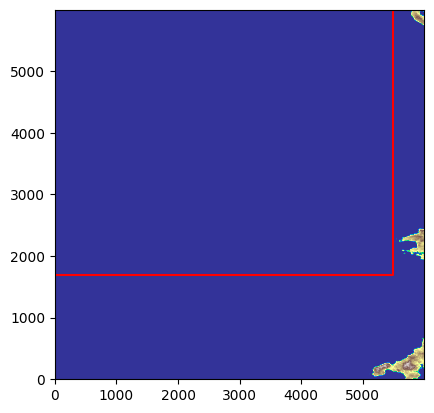

<Figure size 640x480 with 0 Axes>

In [43]:
new_35_02 = loaded_data['35_02'][...]
new_35_02[1700:, :5481] = sea_value

plt.imshow(new_35_02, origin='lower', aspect='equal')
plt.plot( (5481, 5481, 0), (5999, 1700, 1700), c='r' ) # area removed
plt.show()
plt.clf()

### France

This one is slightly simpler as its only within the loaded image `37_02`. That said, a single rectangular selection will be insufficient 

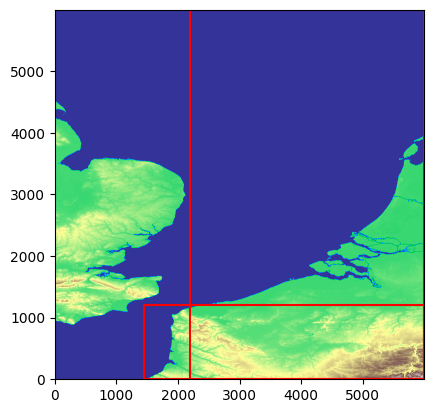

<Figure size 640x480 with 0 Axes>

In [58]:
def plot_rect(ax, 
    xx: list[int], 
    yy: list[int]
):
    ax.plot(
        xx + xx[::-1] + [xx[0]],
        [yy[0]]*2 + [yy[1]]*2 + [yy[0]],
        c='r' 
    )

plt.imshow(loaded_data['37_02'], origin='lower', aspect='equal')
plot_rect( plt.gca(), [1450,5999], [0,1200] ) # [ :1201, 1450: ]
plot_rect( plt.gca(), [2200,5999], [0,5999]) # [ :, 2200: ]
plt.show()
plt.clf()

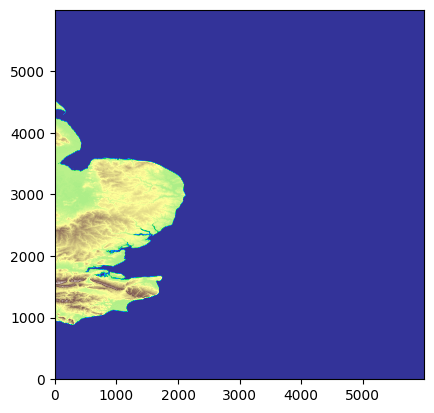

<Figure size 640x480 with 0 Axes>

In [60]:
new_37_02 = loaded_data['37_02'][...]
new_37_02[ :1201, 1450: ] = sea_value
new_37_02[ :, 2200: ] = sea_value

plt.imshow(new_37_02, origin='lower', aspect='equal')
plt.show()
plt.clf()

### Removal of other land

In [4]:
loaded_data['35_01'][:501, :4841] = sea_value
loaded_data['35_02'][1700:, :5481] = sea_value

loaded_data['37_02'][ :1201, 1450: ] = sea_value
loaded_data['37_02'][ :, 2200: ] = sea_value

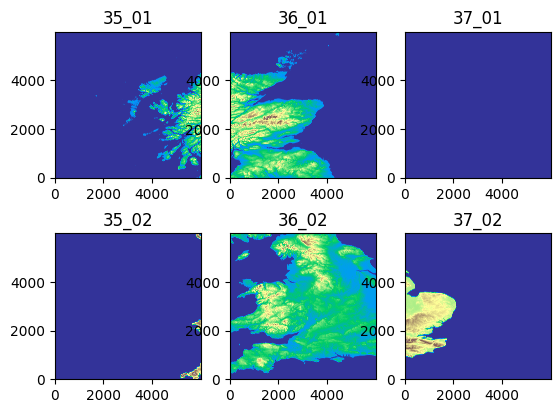

<Figure size 640x480 with 0 Axes>

In [5]:
fig, axs = plt.subplots(2,3)

for r_axs, r_names in zip(axs, row_names):
    for ax, name in zip(r_axs, r_names):
        if name is None:
            continue
        ax.imshow(loaded_data[name], aspect='equal', origin='lower')
        ax.set_title(name)

plt.show()
plt.clf()

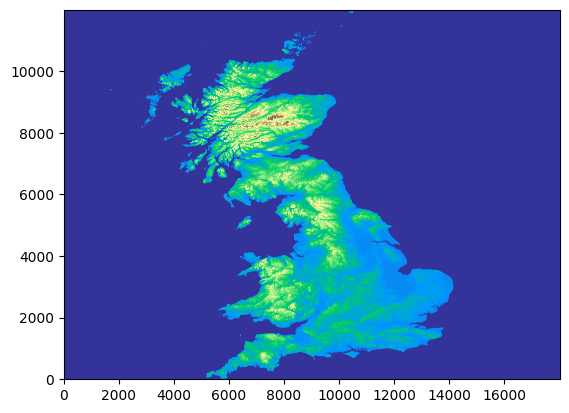

CPU times: user 3.47 s, sys: 2.35 s, total: 5.82 s
Wall time: 6.09 s


<Figure size 640x480 with 0 Axes>

In [6]:
%%time
loaded_data = np.vstack((
    np.hstack(( loaded_data['35_02'], loaded_data['36_02'], loaded_data['37_02'] )),
    np.hstack(( loaded_data['35_01'], loaded_data['36_01'], loaded_data['37_01'] ))
))

plt.imshow(loaded_data, aspect='auto', origin='lower')
plt.show()
plt.clf()

In [55]:
## 55deg North for the XX - YY coords...

es = np.cos(np.deg2rad(55)) # accounting for lines of constant latitude being small-circles, not great-circles like lines of constant longitude


CT = tph.coordtrans.CoordinateTransform(
    ref1Img=[12000, 6000],
    ref1Coords=[0, 55],
    scale=[5/6000 * es, 5/6000], # angle per pixel
)

In [56]:
%%time
x_img = np.arange(18000)
y_img = np.arange(12000)

x_geo, _ = CT.img2Coords(
    [ x_img, x_img ]
)#x_geo.shape, y_geo.shape

_, y_geo = CT.img2Coords(
    [ y_img, y_img ]
)
del _

x_geo.shape, y_geo.shape

CPU times: user 1.5 ms, sys: 2.43 ms, total: 3.94 ms
Wall time: 4.86 ms


((18000,), (12000,))

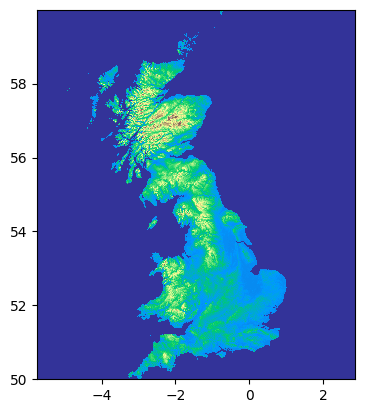

CPU times: user 57.9 s, sys: 17.5 s, total: 1min 15s
Wall time: 1min 22s


<Figure size 640x480 with 0 Axes>

In [57]:
%%time
XXg,YYg = np.meshgrid(x_geo, y_geo)
plt.pcolormesh(XXg, YYg, loaded_data)

plt.gca().set_aspect('equal')

plt.show()
plt.clf()

In [75]:
loaded_data.shape

(12000, 18000)

: 

## Plotting hexagons!!

Some of the hexagons will go off the bottom of the map for now. This will be fixed later by adding in a border of water to the bottom of the image.

The sequence of hexagons will begin in Cornwall and propogate upwards from there.

In [61]:
# initial coordinate => very end of cornwall...
coord_lands_end = [-5.718693, 50.069633] # raw coordinates in decimal degrees
coord_lands_end[0] *= es # extra scaling for longitude conversion
coord_lands_end = np.array(coord_lands_end).reshape((2,1))
coord_lands_end

array([[-3.28010755],
       [50.069633  ]])

In [64]:
# create the hexagon of 200 pixels radius, centered on coords
H = tph.Hexagon(1.75,0,coord_lands_end)


### CODE STOLEN FROM PREVIOUS PROJECT ###
'''
# create all the points in image space
x = range(0,np.size(newD,1))
y = range(0,np.size(newD,0))
X,Y = np.meshgrid(x,y)
print(np.shape(X))

cullMask = H.outsideHexagon_grid(X,Y)
#mask = cullMask.copy()

for j in range(4): # create 4 additional hexagons to the left
    print('j: {}'.format(j))
    H = H.createAdjacentHexagon(3)
    cullMask = np.logical_and(cullMask,H.outsideHexagon_grid(X,Y))
    
#newD[cullMask] = cullValue
'''

cull_value = -500

cull_map = loaded_data.copy()

cull_mask = H.outsideHexagon_grid(XXg, YYg)
cull_map[cull_mask] = cull_value


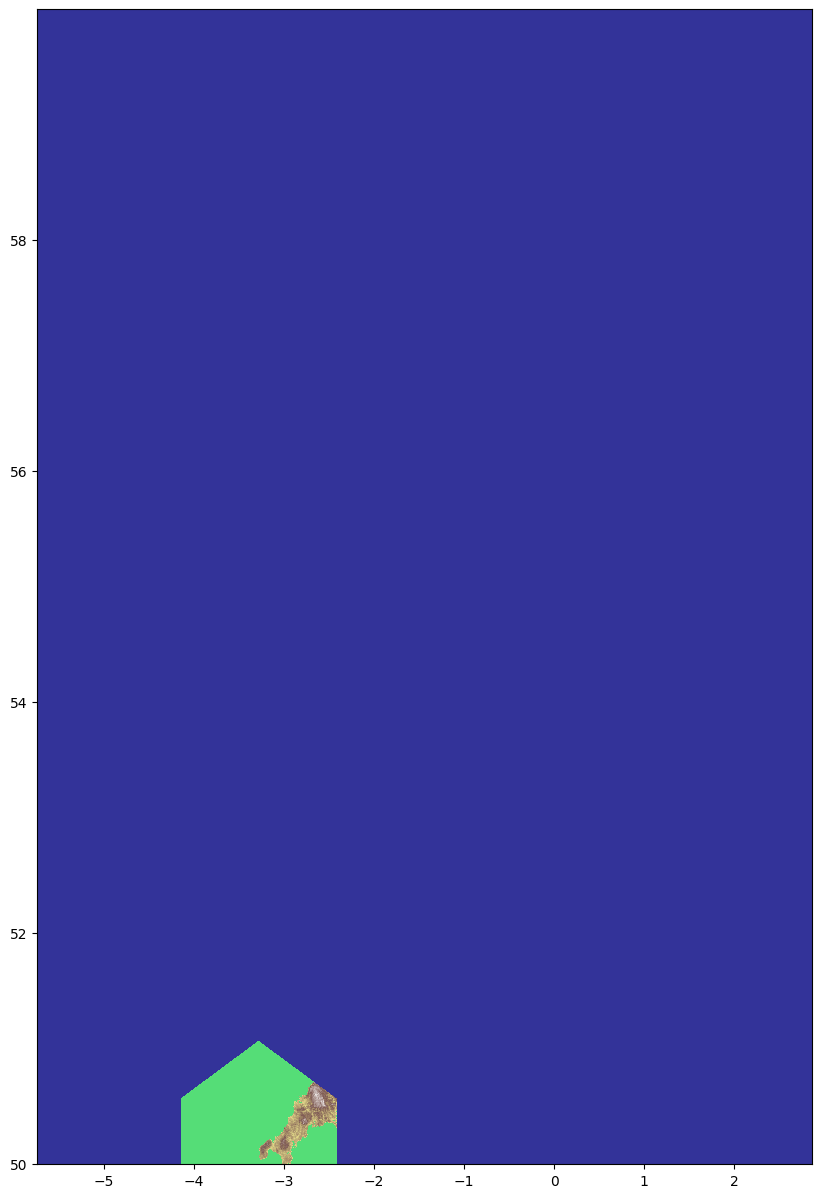

<Figure size 640x480 with 0 Axes>

In [65]:
fig, ax = plt.subplots(1,1,figsize=(10,15))

ax.pcolormesh(XXg,YYg, cull_map)
ax.set_aspect('auto')

plt.show()
plt.clf()

## Serious attempt #1

This one has 7 hexagons that are all roughly -28deg rotated, and we can imagine them as starting from index 0:

0: (-3.555, 55.5985) 

0 ==2==> -1

0 ==1==> -2

0 ==5==> 1

1 ==3==> 2;
0 ==4==> 2

2 ==5==> 3

3 ==3==> 4;
2 ==4==> 4

In [73]:
# long, lat of starting point
# -3.555, 55.985
# -3.555, 55.5
coord_start_geo = np.array([-3.555, 55.5]).reshape((2,1))
coord_start_geo[0] *= es # extra scaling for longitude conversion
print(coord_start_geo)

H0 = tph.Hexagon(1.75, 27, coord_start_geo)

cull_value = -300
cull_map = loaded_data.copy()

cull_mask = H0.outsideHexagon_grid(XXg, YYg)

H0_adjacency = (1,2, 5)
for face in H0_adjacency:
    H = H0.createAdjacentHexagon(face)
    cull_mask = np.logical_and( cull_mask, H.outsideHexagon_grid(XXg, YYg) )

from_H1_faces = (3, 5, 3)
for face in from_H1_faces:
    H = H.createAdjacentHexagon(face)
    cull_mask = np.logical_and( cull_mask, H.outsideHexagon_grid(XXg, YYg) )

cull_map[cull_mask] = cull_value


[[-2.03906423]
 [55.5       ]]


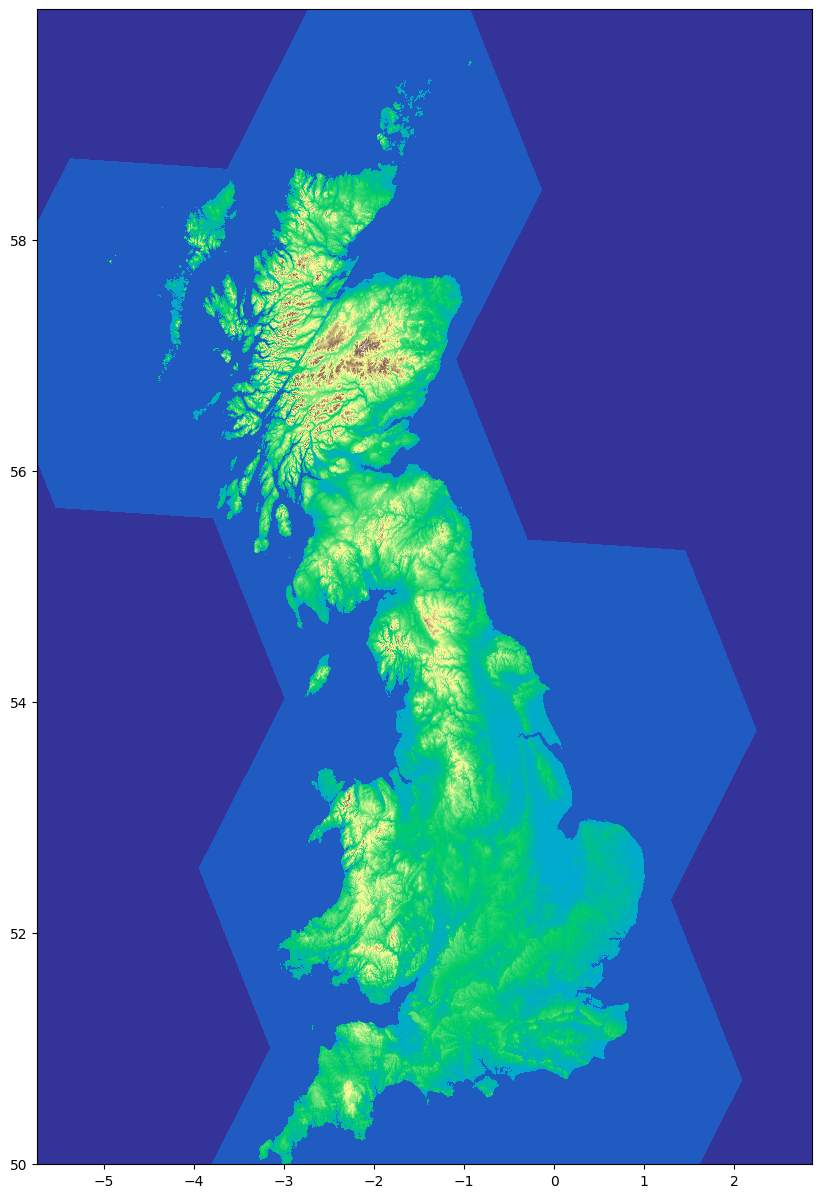

<Figure size 640x480 with 0 Axes>

In [74]:
fig, ax = plt.subplots(1,1,figsize=(10,15))

ax.pcolormesh(XXg,YYg, cull_map)
ax.set_aspect('auto')

plt.show()
plt.clf()